In [0]:
%sql
CREATE VOLUME IF NOT EXISTS workspace.default.retail_volume;

In [0]:
/Volumes/workspace/default/retail_volume/Sample - Superstore.csv

In [0]:
from pyspark.sql import functions as F
from pyspark.sql.functions import (
    col, lit, current_timestamp, input_file_name,
    to_date, year, month, datediff, countDistinct,
    sum as spark_sum, avg, when
)

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score

import joblib
import os
import warnings

warnings.filterwarnings("ignore")

print("All libraries imported successfully!")

All libraries imported successfully!


In [0]:
# PROJECT CONFIGURATION

CATALOG = "workspace"
SCHEMA = "default"

VOLUME_NAME = "retail_volume"

VOLUME_PATH = f"/Volumes/{CATALOG}/{SCHEMA}/{VOLUME_NAME}"

RAW_PATH = f"{VOLUME_PATH}/Sample - Superstore.csv"

print("Project:", "Retail Intelligence Lakehouse")
print("Catalog:", CATALOG)
print("Schema:", SCHEMA)
print("Volume:", VOLUME_PATH)
print("Raw dataset:", RAW_PATH)

# Create volume if it does not exist
spark.sql(f"""
CREATE VOLUME IF NOT EXISTS
{CATALOG}.{SCHEMA}.{VOLUME_NAME}
""")

print("Project configuration completed!")

Project: Retail Intelligence Lakehouse
Catalog: workspace
Schema: default
Volume: /Volumes/workspace/default/retail_volume
Raw dataset: /Volumes/workspace/default/retail_volume/Sample - Superstore.csv
Project configuration completed!


In [0]:
# READ RAW DATA

raw_df = (
    spark.read
    .option("header", True)
    .option("inferSchema", False)
    .option("mode", "PERMISSIVE")
    .csv(RAW_PATH)
)

raw_df = (
    raw_df
    .withColumn("source_file", col("_metadata.file_name"))
    .withColumn("ingested_at", current_timestamp())
)

print("Total raw records:", raw_df.count())

print("Raw dataset schema:")
raw_df.printSchema()

display(raw_df.limit(10))

Total raw records: 9994
Raw dataset schema:
root
 |-- Row ID: string (nullable = true)
 |-- Order ID: string (nullable = true)
 |-- Order Date: string (nullable = true)
 |-- Ship Date: string (nullable = true)
 |-- Ship Mode: string (nullable = true)
 |-- Customer ID: string (nullable = true)
 |-- Customer Name: string (nullable = true)
 |-- Segment: string (nullable = true)
 |-- Country: string (nullable = true)
 |-- City: string (nullable = true)
 |-- State: string (nullable = true)
 |-- Postal Code: string (nullable = true)
 |-- Region: string (nullable = true)
 |-- Product ID: string (nullable = true)
 |-- Category: string (nullable = true)
 |-- Sub-Category: string (nullable = true)
 |-- Product Name: string (nullable = true)
 |-- Sales: string (nullable = true)
 |-- Quantity: string (nullable = true)
 |-- Discount: string (nullable = true)
 |-- Profit: string (nullable = true)
 |-- source_file: string (nullable = false)
 |-- ingested_at: timestamp (nullable = false)



Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit,source_file,ingested_at
1,CA-2016-152156,11-08-2016,11-11-2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.96,2,0,41.9136,Sample%20-%20Superstore.csv,2026-11-14T13:47:44.277Z
2,CA-2016-152156,11-08-2016,11-11-2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs, Rounded Back",731.94,3,0,219.582,Sample%20-%20Superstore.csv,2026-11-14T13:47:44.277Z
3,CA-2016-138688,06-12-2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters by Universal,14.62,2,0,6.8714,Sample%20-%20Superstore.csv,2026-11-14T13:47:44.277Z
4,US-2015-108966,10-11-2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.031,Sample%20-%20Superstore.csv,2026-11-14T13:47:44.277Z
5,US-2015-108966,10-11-2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.368,2,0.2,2.5164,Sample%20-%20Superstore.csv,2026-11-14T13:47:44.277Z
6,CA-2014-115812,06-09-2014,6/14/2014,Standard Class,BH-11710,Brosina Hoffman,Consumer,United States,Los Angeles,California,90032,West,FUR-FU-10001487,Furniture,Furnishings,"Eldon Expressions Wood and Plastic Desk Accessories, Cherry Wood",48.86,7,0,14.1694,Sample%20-%20Superstore.csv,2026-11-14T13:47:44.277Z
7,CA-2014-115812,06-09-2014,6/14/2014,Standard Class,BH-11710,Brosina Hoffman,Consumer,United States,Los Angeles,California,90032,West,OFF-AR-10002833,Office Supplies,Art,Newell 322,7.28,4,0,1.9656,Sample%20-%20Superstore.csv,2026-11-14T13:47:44.277Z
8,CA-2014-115812,06-09-2014,6/14/2014,Standard Class,BH-11710,Brosina Hoffman,Consumer,United States,Los Angeles,California,90032,West,TEC-PH-10002275,Technology,Phones,Mitel 5320 IP Phone VoIP phone,907.152,6,0.2,90.7152,Sample%20-%20Superstore.csv,2026-11-14T13:47:44.277Z
9,CA-2014-115812,06-09-2014,6/14/2014,Standard Class,BH-11710,Brosina Hoffman,Consumer,United States,Los Angeles,California,90032,West,OFF-BI-10003910,Office Supplies,Binders,DXL Angle-View Binders with Locking Rings by Samsill,18.504,3,0.2,5.7825,Sample%20-%20Superstore.csv,2026-11-14T13:47:44.277Z
10,CA-2014-115812,06-09-2014,6/14/2014,Standard Class,BH-11710,Brosina Hoffman,Consumer,United States,Los Angeles,California,90032,West,OFF-AP-10002892,Office Supplies,Appliances,Belkin F5C206VTEL 6 Outlet Surge,114.9,5,0,34.47,Sample%20-%20Superstore.csv,2026-11-14T13:47:44.277Z


In [0]:
# BRONZE LAYER

bronze_table = f"{CATALOG}.{SCHEMA}.bronze_sales"

(
    raw_df.write
    .format("delta")
    .mode("overwrite")
    .option("overwriteSchema", "true")
    .option("delta.columnMapping.mode", "name")
    .saveAsTable(bronze_table)
)

bronze_df = spark.table(bronze_table)

print("Bronze layer created successfully!")
print("Bronze records:", bronze_df.count())

display(bronze_df.limit(10))

Bronze layer created successfully!
Bronze records: 9994


Row ID,Order ID,Order Date,Ship Date,Ship Mode,Customer ID,Customer Name,Segment,Country,City,State,Postal Code,Region,Product ID,Category,Sub-Category,Product Name,Sales,Quantity,Discount,Profit,source_file,ingested_at
1,CA-2016-152156,11-08-2016,11-11-2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.96,2,0,41.9136,Sample%20-%20Superstore.csv,2026-11-14T13:52:06.672Z
2,CA-2016-152156,11-08-2016,11-11-2016,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs, Rounded Back",731.94,3,0,219.582,Sample%20-%20Superstore.csv,2026-11-14T13:52:06.672Z
3,CA-2016-138688,06-12-2016,6/16/2016,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters by Universal,14.62,2,0,6.8714,Sample%20-%20Superstore.csv,2026-11-14T13:52:06.672Z
4,US-2015-108966,10-11-2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.031,Sample%20-%20Superstore.csv,2026-11-14T13:52:06.672Z
5,US-2015-108966,10-11-2015,10/18/2015,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.368,2,0.2,2.5164,Sample%20-%20Superstore.csv,2026-11-14T13:52:06.672Z
6,CA-2014-115812,06-09-2014,6/14/2014,Standard Class,BH-11710,Brosina Hoffman,Consumer,United States,Los Angeles,California,90032,West,FUR-FU-10001487,Furniture,Furnishings,"Eldon Expressions Wood and Plastic Desk Accessories, Cherry Wood",48.86,7,0,14.1694,Sample%20-%20Superstore.csv,2026-11-14T13:52:06.672Z
7,CA-2014-115812,06-09-2014,6/14/2014,Standard Class,BH-11710,Brosina Hoffman,Consumer,United States,Los Angeles,California,90032,West,OFF-AR-10002833,Office Supplies,Art,Newell 322,7.28,4,0,1.9656,Sample%20-%20Superstore.csv,2026-11-14T13:52:06.672Z
8,CA-2014-115812,06-09-2014,6/14/2014,Standard Class,BH-11710,Brosina Hoffman,Consumer,United States,Los Angeles,California,90032,West,TEC-PH-10002275,Technology,Phones,Mitel 5320 IP Phone VoIP phone,907.152,6,0.2,90.7152,Sample%20-%20Superstore.csv,2026-11-14T13:52:06.672Z
9,CA-2014-115812,06-09-2014,6/14/2014,Standard Class,BH-11710,Brosina Hoffman,Consumer,United States,Los Angeles,California,90032,West,OFF-BI-10003910,Office Supplies,Binders,DXL Angle-View Binders with Locking Rings by Samsill,18.504,3,0.2,5.7825,Sample%20-%20Superstore.csv,2026-11-14T13:52:06.672Z
10,CA-2014-115812,06-09-2014,6/14/2014,Standard Class,BH-11710,Brosina Hoffman,Consumer,United States,Los Angeles,California,90032,West,OFF-AP-10002892,Office Supplies,Appliances,Belkin F5C206VTEL 6 Outlet Surge,114.9,5,0,34.47,Sample%20-%20Superstore.csv,2026-11-14T13:52:06.672Z


In [0]:
# SILVER LAYER

silver_df = bronze_df

# Rename columns
column_mapping = {
    "Row ID": "row_id",
    "Order ID": "order_id",
    "Order Date": "order_date",
    "Ship Date": "ship_date",
    "Ship Mode": "ship_mode",
    "Customer ID": "customer_id",
    "Customer Name": "customer_name",
    "Segment": "customer_type",
    "Country": "country",
    "City": "city",
    "State": "state",
    "Postal Code": "postal_code",
    "Region": "region",
    "Product ID": "product_id",
    "Category": "category",
    "Sub-Category": "subcategory",
    "Product Name": "product_name",
    "Sales": "sales",
    "Quantity": "quantity",
    "Discount": "discount",
    "Profit": "profit"
}

for old_name, new_name in column_mapping.items():
    if old_name in silver_df.columns:
        silver_df = silver_df.withColumnRenamed(
            old_name, new_name
        )

# Convert data types
silver_df = (
    silver_df
    .withColumn("row_id", col("row_id").cast("int"))
    .withColumn(
        "order_date",
        F.coalesce(
            F.try_to_date(col("order_date"), "M/d/yyyy"),
            F.try_to_date(col("order_date"), "MM/dd/yyyy"),
            F.try_to_date(col("order_date"), "M-d-yyyy"),
            F.try_to_date(col("order_date"), "MM-dd-yyyy"),
            F.try_to_date(col("order_date"), "yyyy-MM-dd")
        )
    )
    .withColumn(
        "ship_date",
        F.coalesce(
            F.try_to_date(col("ship_date"), "M/d/yyyy"),
            F.try_to_date(col("ship_date"), "MM/dd/yyyy"),
            F.try_to_date(col("ship_date"), "M-d-yyyy"),
            F.try_to_date(col("ship_date"), "MM-dd-yyyy"),
            F.try_to_date(col("ship_date"), "yyyy-MM-dd")
        )
    )
    .withColumn("sales", col("sales").try_cast("double"))
    .withColumn("quantity", col("quantity").try_cast("int"))
    .withColumn("discount", col("discount").try_cast("double"))
    .withColumn("profit", col("profit").try_cast("double"))
)

# Remove duplicate transaction rows
before_count = silver_df.count()

silver_df = silver_df.dropDuplicates(["row_id"])

after_dedup_count = silver_df.count()

# Remove invalid records
silver_df = silver_df.filter(
    col("order_id").isNotNull() &
    col("customer_id").isNotNull() &
    col("product_id").isNotNull() &
    col("order_date").isNotNull() &
    col("sales").isNotNull() &
    col("quantity").isNotNull() &
    (col("quantity") > 0)
)

# Feature engineering
silver_df = silver_df.withColumn(
    "shipping_days",
    datediff(col("ship_date"), col("order_date"))
)

silver_df = silver_df.withColumn(
    "order_year",
    year(col("order_date"))
)

silver_df = silver_df.withColumn(
    "order_month",
    month(col("order_date"))
)

# Store Silver table
silver_table = f"{CATALOG}.{SCHEMA}.silver_sales"

(
    silver_df.write
    .format("delta")
    .mode("overwrite")
    .option("overwriteSchema", "true")
    .saveAsTable(silver_table)
)

print("Silver layer created successfully!")
print("Before deduplication:", before_count)
print("After deduplication:", after_dedup_count)
print("Valid Silver records:", silver_df.count())

display(silver_df.limit(10))

Silver layer created successfully!
Before deduplication: 9994
After deduplication: 9994
Valid Silver records: 9694


row_id,order_id,order_date,ship_date,ship_mode,customer_id,customer_name,customer_type,country,city,state,postal_code,region,product_id,category,subcategory,product_name,sales,quantity,discount,profit,source_file,ingested_at,shipping_days,order_year,order_month
1,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420,South,FUR-BO-10001798,Furniture,Bookcases,Bush Somerset Collection Bookcase,261.96,2,0.0,41.9136,Sample%20-%20Superstore.csv,2026-11-14T13:52:06.672Z,3,2016,11
2,CA-2016-152156,2016-11-08,2016-11-11,Second Class,CG-12520,Claire Gute,Consumer,United States,Henderson,Kentucky,42420,South,FUR-CH-10000454,Furniture,Chairs,"Hon Deluxe Fabric Upholstered Stacking Chairs, Rounded Back",731.94,3,0.0,219.582,Sample%20-%20Superstore.csv,2026-11-14T13:52:06.672Z,3,2016,11
3,CA-2016-138688,2016-06-12,2016-06-16,Second Class,DV-13045,Darrin Van Huff,Corporate,United States,Los Angeles,California,90036,West,OFF-LA-10000240,Office Supplies,Labels,Self-Adhesive Address Labels for Typewriters by Universal,14.62,2,0.0,6.8714,Sample%20-%20Superstore.csv,2026-11-14T13:52:06.672Z,4,2016,6
4,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311,South,FUR-TA-10000577,Furniture,Tables,Bretford CR4500 Series Slim Rectangular Table,957.5775,5,0.45,-383.031,Sample%20-%20Superstore.csv,2026-11-14T13:52:06.672Z,7,2015,10
5,US-2015-108966,2015-10-11,2015-10-18,Standard Class,SO-20335,Sean O'Donnell,Consumer,United States,Fort Lauderdale,Florida,33311,South,OFF-ST-10000760,Office Supplies,Storage,Eldon Fold 'N Roll Cart System,22.368,2,0.2,2.5164,Sample%20-%20Superstore.csv,2026-11-14T13:52:06.672Z,7,2015,10
6,CA-2014-115812,2014-06-09,2014-06-14,Standard Class,BH-11710,Brosina Hoffman,Consumer,United States,Los Angeles,California,90032,West,FUR-FU-10001487,Furniture,Furnishings,"Eldon Expressions Wood and Plastic Desk Accessories, Cherry Wood",48.86,7,0.0,14.1694,Sample%20-%20Superstore.csv,2026-11-14T13:52:06.672Z,5,2014,6
7,CA-2014-115812,2014-06-09,2014-06-14,Standard Class,BH-11710,Brosina Hoffman,Consumer,United States,Los Angeles,California,90032,West,OFF-AR-10002833,Office Supplies,Art,Newell 322,7.28,4,0.0,1.9656,Sample%20-%20Superstore.csv,2026-11-14T13:52:06.672Z,5,2014,6
8,CA-2014-115812,2014-06-09,2014-06-14,Standard Class,BH-11710,Brosina Hoffman,Consumer,United States,Los Angeles,California,90032,West,TEC-PH-10002275,Technology,Phones,Mitel 5320 IP Phone VoIP phone,907.152,6,0.2,90.7152,Sample%20-%20Superstore.csv,2026-11-14T13:52:06.672Z,5,2014,6
9,CA-2014-115812,2014-06-09,2014-06-14,Standard Class,BH-11710,Brosina Hoffman,Consumer,United States,Los Angeles,California,90032,West,OFF-BI-10003910,Office Supplies,Binders,DXL Angle-View Binders with Locking Rings by Samsill,18.504,3,0.2,5.7825,Sample%20-%20Superstore.csv,2026-11-14T13:52:06.672Z,5,2014,6
10,CA-2014-115812,2014-06-09,2014-06-14,Standard Class,BH-11710,Brosina Hoffman,Consumer,United States,Los Angeles,California,90032,West,OFF-AP-10002892,Office Supplies,Appliances,Belkin F5C206VTEL 6 Outlet Surge,114.9,5,0.0,34.47,Sample%20-%20Superstore.csv,2026-11-14T13:52:06.672Z,5,2014,6


In [0]:
# GOLD LAYER

# 1. MONTHLY SALES
gold_monthly = (
    silver_df
    .groupBy("order_year", "order_month")
    .agg(
        F.round(spark_sum("sales"), 2).alias("total_sales"),
        F.round(spark_sum("profit"), 2).alias("total_profit"),
        spark_sum("quantity").alias("total_quantity"),
        countDistinct("order_id").alias("total_orders"),
        countDistinct("customer_id").alias("total_customers")
    )
    .orderBy("order_year", "order_month")
)

# 2. PRODUCT PERFORMANCE
gold_products = (
    silver_df
    .groupBy("category", "subcategory")
    .agg(
        F.round(spark_sum("sales"), 2).alias("total_sales"),
        F.round(spark_sum("profit"), 2).alias("total_profit"),
        spark_sum("quantity").alias("total_quantity"),
        F.round(avg("discount"), 3).alias("average_discount")
    )
    .withColumn(
        "profit_margin",
        F.round(
            when(
                col("total_sales") != 0,
                col("total_profit") / col("total_sales") * 100
            ).otherwise(0),
            2
        )
    )
)

# 3. REGIONAL PERFORMANCE
gold_regions = (
    silver_df
    .groupBy("region", "state")
    .agg(
        F.round(spark_sum("sales"), 2).alias("total_sales"),
        F.round(spark_sum("profit"), 2).alias("total_profit"),
        countDistinct("order_id").alias("total_orders"),
        countDistinct("customer_id").alias("total_customers")
    )
)

# 4. CUSTOMER ANALYTICS
gold_customers = (
    silver_df
    .groupBy("customer_id", "customer_name", "customer_type", "region")
    .agg(
        countDistinct("order_id").alias("frequency"),
        F.round(spark_sum("sales"), 2).alias("monetary"),
        F.max("order_date").alias("last_order_date"),
        F.round(spark_sum("profit"), 2).alias("customer_profit")
    )
)

# Save all Gold tables
gold_tables = {
    "gold_sales_monthly": gold_monthly,
    "gold_products": gold_products,
    "gold_regions": gold_regions,
    "gold_customers": gold_customers
}

for table_name, dataframe in gold_tables.items():

    (
        dataframe.write
        .format("delta")
        .mode("overwrite")
        .option("overwriteSchema", "true")
        .saveAsTable(f"{CATALOG}.{SCHEMA}.{table_name}")
    )

    print(table_name, "created successfully!")

display(gold_monthly)
display(gold_products)
display(gold_regions)
display(gold_customers.limit(10))

gold_sales_monthly created successfully!
gold_products created successfully!
gold_regions created successfully!
gold_customers created successfully!


order_year,order_month,total_sales,total_profit,total_quantity,total_orders,total_customers
2014,1,14161.35,2416.69,271,30,30
2014,2,4119.82,781.84,148,28,27
2014,3,55526.2,419.43,577,71,69
2014,4,28139.56,3450.96,516,66,64
2014,5,23634.67,2732.58,463,68,66
2014,6,34509.0,5054.64,511,66,63
2014,7,33500.87,-926.1,530,63,63
2014,8,27603.51,5353.0,597,72,70
2014,9,81496.81,8214.68,980,127,115
2014,10,31394.94,3452.02,561,77,74


category,subcategory,total_sales,total_profit,total_quantity,average_discount,profit_margin
Furniture,Bookcases,114880.0,-3472.56,868,0.211,-3.02
Furniture,Chairs,328449.1,26590.17,2356,0.17,8.1
Office Supplies,Labels,12486.31,5546.25,1400,0.069,44.42
Furniture,Tables,206965.53,-17725.48,1241,0.261,-8.56
Office Supplies,Storage,216803.21,21527.91,3065,0.075,9.93
Furniture,Furnishings,82752.23,11588.64,3390,0.138,14.0
Office Supplies,Art,27118.79,6527.79,3000,0.075,24.07
Technology,Phones,329753.09,44447.88,3254,0.155,13.48
Office Supplies,Binders,199905.72,29983.02,5614,0.37,15.0
Office Supplies,Appliances,107532.16,18138.01,1729,0.167,16.87


region,state,total_sales,total_profit,total_orders,total_customers
South,Kentucky,36591.75,11199.7,61,58
West,California,450567.59,74669.2,1003,573
South,Florida,88876.88,-3382.71,198,180
South,North Carolina,55548.21,-7486.9,135,121
West,Washington,136590.17,32976.62,249,218
Central,Texas,169553.63,-25534.99,484,369
Central,Wisconsin,32091.89,8391.58,52,51
West,Utah,10575.04,2354.86,23,23
Central,Nebraska,7447.29,2028.45,23,23
East,Pennsylvania,114911.24,-15446.38,276,248


customer_id,customer_name,customer_type,region,frequency,monetary,last_order_date,customer_profit
CG-12520,Claire Gute,Consumer,South,1,993.9,2016-11-08,261.5
DV-13045,Darrin Van Huff,Corporate,West,2,37.6,2016-09-23,17.48
SO-20335,Sean O'Donnell,Consumer,South,2,1438.93,2017-09-09,-319.35
BH-11710,Brosina Hoffman,Consumer,West,1,3714.3,2014-06-09,300.77
AA-10480,Andrew Allen,Consumer,South,1,15.55,2017-04-15,5.44
IM-15070,Irene Maddox,Consumer,West,3,1222.85,2016-12-05,-176.91
HP-14815,Harold Pawlan,Home Office,Central,2,141.47,2015-11-22,-106.64
PK-19075,Pete Kriz,Consumer,Central,3,1234.04,2017-03-05,112.47
AG-10270,Alejandro Grove,Consumer,West,1,55.5,2014-05-13,9.99
ZD-21925,Zuschuss Donatelli,Consumer,West,2,306.2,2017-06-11,42.47


In [0]:
%sql
SELECT
    ROUND(SUM(sales), 2) AS total_sales,
    ROUND(SUM(profit), 2) AS total_profit,
    COUNT(DISTINCT order_id) AS total_orders,
    COUNT(DISTINCT customer_id) AS total_customers,
    SUM(quantity) AS units_sold,
    ROUND(
        SUM(profit) / SUM(sales) * 100, 2
    ) AS profit_margin_percentage
FROM workspace.default.silver_sales;

total_sales,total_profit,total_orders,total_customers,units_sold,profit_margin_percentage
2272449.86,282857.75,4931,793,36749,12.45


In [0]:
%sql
SELECT
    category,
    ROUND(SUM(sales), 2) AS revenue,
    ROUND(SUM(profit), 2) AS profit,
    SUM(quantity) AS units_sold
FROM workspace.default.silver_sales
GROUP BY category
ORDER BY revenue DESC;

category,revenue,profit,units_sold
Technology,835900.07,145387.1,6904
Furniture,733046.86,16980.77,7855
Office Supplies,703502.93,120489.89,21990


In [0]:
%sql
SELECT
    order_year,
    order_month,
    ROUND(SUM(sales), 2) AS monthly_revenue,
    ROUND(SUM(profit), 2) AS monthly_profit
FROM workspace.default.silver_sales
GROUP BY order_year, order_month
ORDER BY order_year, order_month;

order_year,order_month,monthly_revenue,monthly_profit
2014,1,14161.35,2416.69
2014,2,4119.82,781.84
2014,3,55526.2,419.43
2014,4,28139.56,3450.96
2014,5,23634.67,2732.58
2014,6,34509.0,5054.64
2014,7,33500.87,-926.1
2014,8,27603.51,5353.0
2014,9,81496.81,8214.68
2014,10,31394.94,3452.02


In [0]:
%sql
SELECT
    customer_id,
    customer_name,
    COUNT(DISTINCT order_id) AS orders,
    ROUND(SUM(sales), 2) AS revenue,
    ROUND(SUM(profit), 2) AS profit
FROM workspace.default.silver_sales
GROUP BY customer_id, customer_name
ORDER BY revenue DESC
LIMIT 10;

customer_id,customer_name,orders,revenue,profit
SM-20320,Sean Miller,5,25043.05,-1980.74
TC-20980,Tamara Chand,5,19017.85,8964.48
RB-19360,Raymond Buch,6,15117.34,6976.1
TA-21385,Tom Ashbrook,4,14595.62,4703.79
AB-10105,Adrian Barton,9,14355.61,5438.91
SC-20095,Sanjit Chand,9,14142.33,5757.41
KL-16645,Ken Lonsdale,10,14071.92,768.87
HL-15040,Hunter Lopez,6,12873.3,5622.43
SE-20110,Sanjit Engle,11,12209.44,2650.68
CC-12370,Christopher Conant,5,12129.07,2177.05


In [0]:
%sql
SELECT
    product_name,
    category,
    ROUND(SUM(sales), 2) AS sales,
    ROUND(SUM(profit), 2) AS profit
FROM workspace.default.silver_sales
GROUP BY product_name, category
HAVING SUM(profit) < 0
ORDER BY profit ASC
LIMIT 20;

product_name,category,sales,profit
Cubify CubeX 3D Printer Double Head Print,Technology,11099.96,-8879.97
Lexmark MX611dhe Monochrome Laser Printer,Technology,16829.9,-4589.97
Cubify CubeX 3D Printer Triple Head Print,Technology,7999.98,-3839.99
Chromcraft Bull-Nose Wood Oval Conference Tables & Bases,Furniture,9917.64,-2876.12
Bush Advantage Collection Racetrack Conference Table,Furniture,9544.73,-1934.4
GBC DocuBind P400 Electric Binding System,Office Supplies,17965.07,-1878.17
Cisco TelePresence System EX90 Videoconferencing Unit,Technology,22638.48,-1811.08
Martin Yale Chadless Opener Electric Letter Opener,Office Supplies,16656.2,-1299.18
Balt Solid Wood Round Tables,Furniture,6518.75,-1201.06
BoxOffice By Design Rectangular and Half-Moon Meeting Room Tables,Furniture,1706.25,-1148.44


In [0]:
# RFM FEATURE ENGINEERING

# Reference date: day after the latest order in the dataset
max_order_date = silver_df.agg(
    F.max("order_date").alias("max_date")
).first()["max_date"]

reference_date = F.date_add(
    F.lit(max_order_date), 1
)

rfm_df = (
    silver_df
    .groupBy("customer_id", "customer_name")
    .agg(
        datediff(
            reference_date,
            F.max("order_date")
        ).alias("recency"),

        countDistinct("order_id").alias("frequency"),

        F.round(
            spark_sum("sales"), 2
        ).alias("monetary")
    )
)

print("RFM features generated!")

display(rfm_df.limit(15))

RFM features generated!


customer_id,customer_name,recency,frequency,monetary
CG-12520,Claire Gute,339,3,1148.78
DV-13045,Darrin Van Huff,20,5,1119.48
SO-20335,Sean O'Donnell,30,6,2602.58
BH-11710,Brosina Hoffman,24,8,6255.35
AA-10480,Andrew Allen,260,4,1782.87
IM-15070,Irene Maddox,391,7,4930.47
HP-14815,Harold Pawlan,31,7,1990.31
PK-19075,Pete Kriz,10,12,8158.65
AG-10270,Alejandro Grove,279,5,2565.26
ZD-21925,Zuschuss Donatelli,203,5,1493.94


In [0]:
# K-MEANS CUSTOMER SEGMENTATION

# Convert to Pandas
rfm_pd = rfm_df.toPandas()

# Prepare features
features = ["recency", "frequency", "monetary"]

X = rfm_pd[features].astype(float)

# Log transformation to reduce skew
X_log = np.log1p(X)

# Standardization
scaler = StandardScaler()

X_scaled = scaler.fit_transform(X_log)

# Train K-Means
kmeans = KMeans(
    n_clusters=4,
    random_state=42,
    n_init=10
)

rfm_pd["cluster_id"] = kmeans.fit_predict(X_scaled)

# Model evaluation
silhouette = silhouette_score(
    X_scaled,
    rfm_pd["cluster_id"]
)

print("K-Means model trained!")
print("Number of clusters:", 4)
print("Silhouette score:", round(silhouette, 4))

# Determine segment names using average spending
cluster_spending = (
    rfm_pd.groupby("cluster_id")["monetary"]
    .mean()
    .sort_values()
)

segment_names = [
    "Low Value",
    "Mid Value",
    "High Value",
    "Top Value"
]

cluster_mapping = {
    int(cluster_id): segment_names[i]
    for i, cluster_id in enumerate(cluster_spending.index)
}

rfm_pd["customer_segment"] = (
    rfm_pd["cluster_id"].map(cluster_mapping)
)

print("\nCustomer segment mapping:")
print(cluster_mapping)

display(rfm_pd.head(15))

K-Means model trained!
Number of clusters: 4
Silhouette score: 0.2566

Customer segment mapping:
{2: 'Low Value', 0: 'Mid Value', 3: 'High Value', 1: 'Top Value'}


customer_id,customer_name,recency,frequency,monetary,cluster_id,customer_segment
CG-12520,Claire Gute,339,3,1148.78,0,Mid Value
DV-13045,Darrin Van Huff,20,5,1119.48,3,High Value
SO-20335,Sean O'Donnell,30,6,2602.58,3,High Value
BH-11710,Brosina Hoffman,24,8,6255.35,1,Top Value
AA-10480,Andrew Allen,260,4,1782.87,0,Mid Value
IM-15070,Irene Maddox,391,7,4930.47,1,Top Value
HP-14815,Harold Pawlan,31,7,1990.31,3,High Value
PK-19075,Pete Kriz,10,12,8158.65,1,Top Value
AG-10270,Alejandro Grove,279,5,2565.26,0,Mid Value
ZD-21925,Zuschuss Donatelli,203,5,1493.94,0,Mid Value


Customers in each segment:
customer_segment
Mid Value     269
Top Value     244
High Value    189
Low Value      91
Name: count, dtype: int64


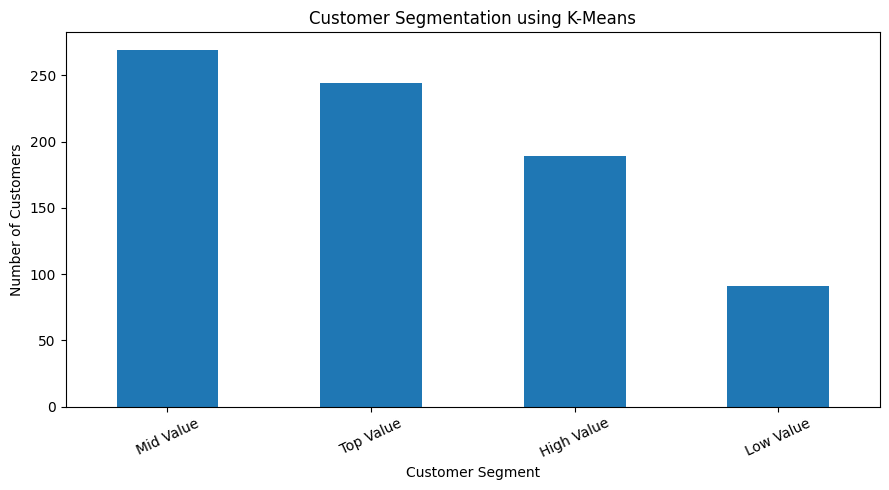

In [0]:
# CUSTOMER SEGMENT DISTRIBUTION

segment_counts = (
    rfm_pd["customer_segment"]
    .value_counts()
)

print("Customers in each segment:")
print(segment_counts)

plt.figure(figsize=(9, 5))

segment_counts.plot(kind="bar")

plt.title("Customer Segmentation using K-Means")
plt.xlabel("Customer Segment")
plt.ylabel("Number of Customers")
plt.xticks(rotation=25)
plt.tight_layout()
plt.show()

In [0]:
# CLUSTER PERFORMANCE

cluster_summary = (
    rfm_pd
    .groupby("customer_segment")
    .agg(
        customers=("customer_id", "count"),
        avg_recency=("recency", "mean"),
        avg_frequency=("frequency", "mean"),
        avg_monetary=("monetary", "mean")
    )
    .round(2)
)

display(cluster_summary)

customers,avg_recency,avg_frequency,avg_monetary
189,19.88,6.67,2509.18
91,352.78,2.53,470.09
269,231.92,5.08,1981.88
244,90.14,8.5,5009.46


In [0]:
# SAVE MODEL

model_artifact = {
    "scaler": scaler,
    "kmeans": kmeans,
    "features": features,
    "cluster_mapping": cluster_mapping,
    "reference_date": str(max_order_date)
}

joblib.dump(
    model_artifact,
    VOLUME_PATH + "/customer_segmentation_model.joblib"
)

print("ML model saved successfully!")

# SAVE CUSTOMER SEGMENTATION TABLE

customer_segments_spark = spark.createDataFrame(rfm_pd)

(
    customer_segments_spark.write
    .format("delta")
    .mode("overwrite")
    .option("overwriteSchema", "true")
    .saveAsTable(
        f"{CATALOG}.{SCHEMA}.gold_customer_segments"
    )
)

display(customer_segments_spark)

ML model saved successfully!


customer_id,customer_name,recency,frequency,monetary,cluster_id,customer_segment
CG-12520,Claire Gute,339,3,1148.78,0,Mid Value
DV-13045,Darrin Van Huff,20,5,1119.48,3,High Value
SO-20335,Sean O'Donnell,30,6,2602.58,3,High Value
BH-11710,Brosina Hoffman,24,8,6255.35,1,Top Value
AA-10480,Andrew Allen,260,4,1782.87,0,Mid Value
IM-15070,Irene Maddox,391,7,4930.47,1,Top Value
HP-14815,Harold Pawlan,31,7,1990.31,3,High Value
PK-19075,Pete Kriz,10,12,8158.65,1,Top Value
AG-10270,Alejandro Grove,279,5,2565.26,0,Mid Value
ZD-21925,Zuschuss Donatelli,203,5,1493.94,0,Mid Value


In [0]:
# FINAL POWER BI DATASET

segments_df = customer_segments_spark.select(
    "customer_id",
    "customer_segment",
    "cluster_id",
    "recency",
    "frequency",
    "monetary"
)

gold_retail = (
    silver_df
    .join(
        segments_df,
        on="customer_id",
        how="left"
    )
    .withColumn(
        "profit_margin_pct",
        F.round(
            when(
                col("sales") != 0,
                col("profit") / col("sales") * 100
            ).otherwise(0),
            2
        )
    )
    .withColumn(
        "order_to_ship_days",
        datediff(col("ship_date"), col("order_date"))
    )
)

gold_retail_table = (
    f"{CATALOG}.{SCHEMA}.gold_retail_powerbi"
)

(
    gold_retail.write
    .format("delta")
    .mode("overwrite")
    .option("overwriteSchema", "true")
    .saveAsTable(gold_retail_table)
)

print("Final Power BI Gold table created!")

display(gold_retail.limit(10))

Final Power BI Gold table created!


customer_id,row_id,order_id,order_date,ship_date,ship_mode,customer_name,customer_type,country,city,state,postal_code,region,product_id,category,subcategory,product_name,sales,quantity,discount,profit,source_file,ingested_at,shipping_days,order_year,order_month,customer_segment,cluster_id,recency,frequency,monetary,profit_margin_pct,order_to_ship_days
BH-11710,12,CA-2014-115812,2014-06-09,2014-06-14,Standard Class,Brosina Hoffman,Consumer,United States,Los Angeles,California,90032,West,TEC-PH-10002033,Technology,Phones,Konftel 250 Conference phone - Charcoal black,911.424,4,0.2,68.3568,Sample%20-%20Superstore.csv,2026-11-14T13:52:06.672Z,5,2014,6,Top Value,1,24,8,6255.35,7.5,5
AG-10270,18,CA-2014-167164,2014-05-13,2014-05-15,Second Class,Alejandro Grove,Consumer,United States,West Jordan,Utah,84084,West,OFF-ST-10000107,Office Supplies,Storage,Fellowes Super Stor/Drawer,55.5,2,0.0,9.99,Sample%20-%20Superstore.csv,2026-11-14T13:52:06.672Z,2,2014,5,Mid Value,0,279,5,2565.26,18.0,2
SN-20710,38,CA-2015-117415,2015-12-27,2015-12-31,Standard Class,Steve Nguyen,Home Office,United States,Houston,Texas,77041,Central,OFF-EN-10002986,Office Supplies,Envelopes,"""#10-4 1/8"""" x 9 1/2"""" Premium Diagonal Seam Envelopes""",113.328,9,0.2,35.415,Sample%20-%20Superstore.csv,2026-11-14T13:52:06.672Z,4,2015,12,Top Value,1,80,7,3127.96,31.25,4
PS-18970,67,US-2015-164175,2015-04-30,2015-05-05,Standard Class,Paul Stevenson,Home Office,United States,Chicago,Illinois,60610,Central,FUR-CH-10001146,Furniture,Chairs,"Global Value Mid-Back Manager's Chair, Gray",213.115,5,0.3,-15.2225,Sample%20-%20Superstore.csv,2026-11-14T13:52:06.672Z,5,2015,4,Top Value,1,70,8,1278.64,-7.14,5
KD-16270,70,CA-2016-119823,2016-06-04,2016-06-06,First Class,Karen Daniels,Consumer,United States,Springfield,Virginia,22153,South,OFF-PA-10000482,Office Supplies,Paper,"Snap-A-Way Black Print Carbonless Ruled Speed Letter, Triplicate",75.88,2,0.0,35.6636,Sample%20-%20Superstore.csv,2026-11-14T13:52:06.672Z,2,2016,6,Mid Value,0,485,5,8282.36,47.0,2
KB-16315,93,CA-2015-149587,2015-01-31,2015-02-05,Second Class,Karl Braun,Consumer,United States,Minneapolis,Minnesota,55407,Central,OFF-PA-10003177,Office Supplies,Paper,Xerox 1999,12.96,2,0.0,6.2208,Sample%20-%20Superstore.csv,2026-11-14T13:52:06.672Z,5,2015,1,Mid Value,0,297,9,1569.46,48.0,5
TT-21070,161,CA-2016-162733,2016-05-11,2016-05-12,First Class,Ted Trevino,Consumer,United States,Los Angeles,California,90045,West,OFF-PA-10002751,Office Supplies,Paper,Xerox 1920,5.98,1,0.0,2.691,Sample%20-%20Superstore.csv,2026-11-14T13:52:06.672Z,1,2016,5,Top Value,1,32,7,4915.6,45.0,1
SK-19990,186,CA-2016-105018,2016-11-28,2016-12-02,Standard Class,Sally Knutson,Consumer,United States,Fairfield,Connecticut,6824,East,OFF-BI-10001890,Office Supplies,Binders,Avery Poly Binder Pockets,7.16,2,0.0,3.4368,Sample%20-%20Superstore.csv,2026-11-14T13:52:06.672Z,4,2016,11,High Value,3,9,3,883.41,48.0,4
MP-17470,190,CA-2015-102281,2015-10-12,2015-10-14,First Class,Mark Packer,Home Office,United States,New York City,New York,10035,East,FUR-BO-10002613,Furniture,Bookcases,"Atlantic Metals Mobile 4-Shelf Bookcases, Custom Colors",899.136,4,0.2,112.392,Sample%20-%20Superstore.csv,2026-11-14T13:52:06.672Z,2,2015,10,Mid Value,0,720,7,3206.13,12.5,2
JH-15910,218,CA-2016-130162,2016-10-28,2016-11-01,Standard Class,Jonathan Howell,Consumer,United States,Los Angeles,California,90032,West,OFF-ST-10001328,Office Supplies,Storage,"Personal Filing Tote with Lid, Black/Gray",93.06,6,0.0,26.0568,Sample%20-%20Superstore.csv,2026-11-14T13:52:06.672Z,4,2016,10,High Value,3,42,7,959.48,28.0,4


In [0]:
# EXPORT GOLD DATA FOR POWER BI

powerbi_pd = gold_retail.toPandas()

powerbi_pd["order_date"] = pd.to_datetime(
    powerbi_pd["order_date"]
)

powerbi_pd["ship_date"] = pd.to_datetime(
    powerbi_pd["ship_date"]
)

# Export Power BI fact table
powerbi_pd.to_csv(
    VOLUME_PATH + "/gold_retail_powerbi.csv",
    index=False
)

# Export customer segmentation separately
rfm_pd.to_csv(
    VOLUME_PATH + "/gold_customer_segments.csv",
    index=False
)

print("Power BI datasets exported successfully!")

Power BI datasets exported successfully!


In [0]:
# FINAL PROJECT VALIDATION

print("====================================")
print("RETAIL INTELLIGENCE LAKEHOUSE")
print("FINAL VALIDATION")
print("====================================")

print("Bronze records:",
      spark.table(
          f"{CATALOG}.{SCHEMA}.bronze_sales"
      ).count())

print("Silver records:",
      spark.table(
          f"{CATALOG}.{SCHEMA}.silver_sales"
      ).count())

print("Gold Power BI records:",
      spark.table(
          f"{CATALOG}.{SCHEMA}.gold_retail_powerbi"
      ).count())

print("Unique customers:",
      rfm_pd["customer_id"].nunique())

print("Customer clusters:",
      rfm_pd["customer_segment"].nunique())

print("Model silhouette score:",
      round(silhouette, 4))

print("====================================")
print("PROJECT PIPELINE COMPLETED!")
print("====================================")

display(dbutils.fs.ls(VOLUME_PATH))

RETAIL INTELLIGENCE LAKEHOUSE
FINAL VALIDATION
Bronze records: 9994
Silver records: 9694
Gold Power BI records: 9694
Unique customers: 793
Customer clusters: 4
Model silhouette score: 0.2566
PROJECT PIPELINE COMPLETED!


path,name,size,modificationTime
dbfs:/Volumes/workspace/default/retail_volume/Sample - Superstore.csv,Sample - Superstore.csv,2299310,1794663515000
dbfs:/Volumes/workspace/default/retail_volume/customer_segmentation_model.joblib,customer_segmentation_model.joblib,4866,1794666145000
dbfs:/Volumes/workspace/default/retail_volume/gold_customer_segments.csv,gold_customer_segments.csv,38408,1794666445000
dbfs:/Volumes/workspace/default/retail_volume/gold_retail_powerbi.csv,gold_retail_powerbi.csv,3175730,1794666445000
